In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
from astropy import units as u
import emcee
from matplotlib import pyplot as plt
import corner

from load_galweight_data import load_clusters
from cluster import temp_from_vdisp
from statistics_functions import log_likelihood, chi_squared
from cluster_functions import *

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [3]:
# get dataset
n=20
clusters, variances = load_clusters(nrows=n)

In [4]:
pref_theo = 6.8*1e-42 *u.erg*u.cm**3

In [5]:
test_cluster=clusters[0]

In [34]:
p0=[-25, -2]
getattr(test_cluster, 'pred_pref')(p0)

<Quantity 5.4478908e-94 s / cm3>

In [51]:
pref_pred = [getattr(c, 'pred_pref')(p0) for c in clusters]
pref_pred

1.1057639847979102e-07 GeV 1.133690517119171e-05 GeV
8.498923710713636e-08 GeV 8.966433110487784e-06 GeV
8.13813003498707e-08 GeV 9.079899761377789e-06 GeV
7.608212662875618e-08 GeV 8.107454272960878e-06 GeV
7.518549651300869e-08 GeV 7.4128508780469744e-06 GeV
7.356158608028455e-08 GeV 8.203686559654766e-06 GeV
7.344519152057315e-08 GeV 8.225295726239415e-06 GeV
7.18282444599984e-08 GeV 7.725049346969507e-06 GeV
6.905310158134068e-08 GeV 7.33483837714982e-06 GeV
6.780800124727961e-08 GeV 6.211060421417403e-06 GeV
6.860705481517105e-08 GeV 7.482400039714647e-06 GeV
6.59219634420343e-08 GeV 7.2500302954917555e-06 GeV
6.42324822353322e-08 GeV 7.74834976193562e-06 GeV
6.165903187026066e-08 GeV 8.05491992778816e-06 GeV
5.9114994442269725e-08 GeV 5.924391289571273e-06 GeV
5.745906988537711e-08 GeV 5.611445679868858e-06 GeV
5.607511825216782e-08 GeV 5.386107882777741e-06 GeV
5.75538275889545e-08 GeV 3.2463230783476785e-06 GeV
5.6173436835953885e-08 GeV 4.88330641499075e-06 GeV
5.6411758312902

TypeError: only integer dimensionless scalar quantities can be converted to a Python index

In [49]:
data=np.ones(n)*6.8*1e-42 *u.erg*u.cm**3
data

<Quantity [6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42,
           6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42,
           6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42] cm3 erg>

In [52]:
var = [p/10 for p in pref_pred] # made up variance for now, implement variance for mcxc

In [68]:
ndim, nwalkers = 2, 20
log_sigma0 = np.random.uniform(low=-30, high=-10, size=(nwalkers, 1)).astype(dtype=np.float128)
log_mchi = np.random.uniform(low=-10, high=0, size=(nwalkers, 1)).astype(dtype=np.float128)

p0=np.zeros((nwalkers, ndim ))
p0[:,0] = log_sigma0.reshape((nwalkers,))
p0[:,1]= log_mchi.reshape((nwalkers,))
p0

array([[-15.07871236,  -7.41496056],
       [-28.29225959,  -7.23711009],
       [-14.23413335,  -7.2012581 ],
       [-22.89806272,  -9.38957318],
       [-29.55415474,  -8.35961815],
       [-15.92139787,  -2.84609761],
       [-17.30807247,  -7.02376006],
       [-27.02987748,  -2.85859407],
       [-26.36273089,  -5.34309532],
       [-29.86665753,  -7.83868427],
       [-28.90691967,  -2.76218515],
       [-14.35874054,  -6.50800618],
       [-19.19829537,  -4.23732415],
       [-28.51518237,  -1.97534066],
       [-22.31178824,  -3.25484177],
       [-23.10897983,  -6.17563881],
       [-10.97245856,  -1.19839239],
       [-24.90975879,  -0.88341625],
       [-12.75249592,  -3.89818805],
       [-11.65285908,  -2.55474858]])

In [204]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_likelihood, args=[data, var, clusters, 'pred_pref'])

In [205]:
state = sampler.run_mcmc(p0, 100, progress=True)
sampler.reset()

emcee: Exception while calling your likelihood function:
  params: [-43.15767981]
  args: [<Quantity [6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42,
           6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42,
           6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42, 6.8e-42] cm3 erg>, [<Quantity 3.45306943e-42 cm3 erg>, <Quantity 2.71334459e-42 cm3 erg>, <Quantity 2.71367357e-42 cm3 erg>, <Quantity 2.44788463e-42 cm3 erg>, <Quantity 2.27836895e-42 cm3 erg>, <Quantity 2.45204902e-42 cm3 erg>, <Quantity 2.45623827e-42 cm3 erg>, <Quantity 2.32761064e-42 cm3 erg>, <Quantity 2.21620793e-42 cm3 erg>, <Quantity 1.94269735e-42 cm3 erg>, <Quantity 2.2474943e-42 cm3 erg>, <Quantity 2.17366097e-42 cm3 erg>, <Quantity 2.2772039e-42 cm3 erg>, <Quantity 2.32878763e-42 cm3 erg>, <Quantity 1.81397828e-42 cm3 erg>, <Quantity 1.72854855e-42 cm3 erg>, <Quantity 1.66563892e-42 cm3 erg>, <Quantity 1.1566739e-42 cm3 erg>, <Quantity 1.54708395e-42 cm3 erg>, <Quantity 1.77855028e-4

Traceback (most recent call last):
  File "/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/emcee/ensemble.py", line 624, in __call__
    return self.f(x, *self.args, **self.kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py", line 23, in log_likelihood
    model = [getattr(c, pred_func)(p0) for c in clusters]
            ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py", line 23, in <listcomp>
    model = [getattr(c, pred_func)(p0) for c in clusters]
             ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster.py", line 244, in pred_pref
    m_chi = 10 ** p0[1] * u.GeV
                  ~~^^^
IndexError: index 1 is out of bounds for axis 0 with size 1


IndexError: index 1 is out of bounds for axis 0 with size 1

In [71]:
n_steps=10000
sampler.run_mcmc(state, n_steps, progress=True)

You must install the tqdm library to use progress indicators with emcee


[-25.49603015  -6.36786996]
[-25.53498923  -0.94755915]
[-25.53984036  -4.98204026]
[-25.46698834  -6.47719959]
[-25.51830842  -7.39590604]
[-25.53604548  -4.93593281]
[-25.5182065   -3.78030493]
[-25.48004481  -4.10901833]
[-25.50360388  -4.49077422]
[-25.42384168  -1.0502371 ]
[-25.47382555  -2.03054727]
[-25.50068955  -3.58765124]
[-25.59754117  -8.00510645]
[-25.50652231  -9.73109109]
[-25.53715635  -3.150786  ]
[-25.24413607  -1.94283955]
[-25.50564209  -7.03789584]
[-25.50385986  -5.66895811]
[-25.6101347   -8.03393163]
[-25.52529871  -2.95860808]
[-25.56450533  -6.56787969]
[-25.44290345  -8.54224195]
[-25.50453366  -2.9909807 ]
[-25.53447733  -4.83434643]
[-25.53300645  -4.42644341]
[-25.50167983  -3.43394326]
[-25.51057222  -5.58271716]
[-25.53633956  -3.66407572]
[-25.53806664  -7.04176285]
[-25.51242094  -3.83014006]
[-25.50497751  -7.02490789]
[-25.4675009   -6.21455177]
[-24.74161797  -0.14870939]
[-25.42815534  -1.3165728 ]
[-25.49117375  -5.75682181]
[-25.52634428  -2.77

[-25.47628104  -2.46194807]
[-24.92573909  -0.45689331]
[-25.50926978  -4.38134973]
[-25.54452259  -9.39144707]
[-25.45159343  -1.2628707 ]
[-25.42846211  -9.81954985]
[-25.46956273  -5.89229816]
[-25.48473683  -7.77727704]
[-25.9257202   -9.88133029]
[-25.52540315  -1.78941899]
[-25.5009356  -6.8256508]
[-25.53727986  -6.57440794]
[-25.48424359  -2.29839667]
[-25.46730602  -5.10918578]
[-25.49078568  -4.20090706]
[-25.52623832  -8.29919556]
[-25.55291894  -5.61357259]
[-25.4413342   -1.12212805]
[-25.47565165  -2.35054976]
[-24.83979126  -0.21581791]
[-25.49944084  -3.95660303]
[-25.48515035  -2.29289263]
[-25.46530434  -4.80279404]
[-25.51974201  -8.72239021]
[-25.46236917  -3.43966706]
[-25.47801151  -7.33536301]
[-25.50433508  -7.40130047]
[-25.52813906  -1.7585615 ]
[-25.50918747  -9.16628055]
[-25.55882545  -8.34399649]
[-26.07894466  -7.74858773]
[-25.33061192  -6.28191064]
[-25.53661524  -7.77149895]
[-25.56655782  -2.3741413 ]
[-25.53850527  -6.14394846]
[-25.50209645  -7.0222

[-25.52708511  -9.4252572 ]
[-25.47103479  -5.75826738]
[-25.47562418  -6.37448379]
[-25.51505389  -6.39787558]
[-25.47784557  -7.20802543]
[-25.46634588  -7.40121452]
[-25.45497054  -4.11883481]
[-25.56104466  -1.78838086]
[-25.50176384  -8.30705224]
[-25.47162329  -5.87932599]
[-25.49669124  -7.66352453]
[-25.51211772  -4.81686945]
[-25.46668329  -7.43750305]
[-25.46640519  -4.63230902]
[-25.47601666  -7.77920659]
[-25.48224658  -7.44515665]
[-25.47074487  -5.60718592]
[-25.46588224  -6.28263831]
[-25.48144532  -7.01022891]
[-25.50833277  -3.5333985 ]
[-25.48329415  -4.92108038]
[-25.42556324  -0.16120711]
[-25.46633766  -7.78468012]
[-25.45579408  -4.15581595]
[-25.5279793  -6.1814122]
[-25.52192375  -5.62547137]
[-25.52862651  -9.38593234]
[-25.47960836  -5.48532916]
[-24.88618679  -0.87503075]
[-25.51281257  -6.74408763]
[-25.48117015  -4.86197435]
[-25.47512741  -5.60214116]
[-25.46637021  -6.26536047]
[-25.52723341  -9.42147357]
[-25.45010504  -5.76668339]
[-25.47325195  -6.1703

[-25.45207005  -5.6093301 ]
[-25.45343921  -6.75274454]
[-25.52162192  -1.72444356]
[-25.48815404  -2.60197145]
[-25.48515716  -9.69597164]
[-25.48826605  -1.77935523]
[-25.50492583  -7.52363846]
[-25.46994377  -6.44201752]
[-25.42322192  -1.01957257]
[-25.48205387  -5.07549812]
[-25.4716877   -8.66921619]
[-25.45119867  -3.76091045]
[-25.54341337  -8.6637295 ]
[-25.5494867   -6.28012282]
[-25.49542239  -7.18383778]
[-25.5250294   -5.29174261]
[-25.48275979  -7.44855883]
[-25.02839222  -2.84149347]
[-25.49878513  -9.34067377]
[-25.51715272  -2.38272562]
[-25.41044002  -8.67390136]
[-25.48721715  -9.77987503]
[-25.51073703  -7.6560933 ]
[-25.55418401  -4.69675967]
[-25.46954633  -6.45858297]
[-25.45781644  -7.45188399]
[-25.71312259  -6.80689479]
[-25.45227821  -6.77643803]
[-25.54158417  -8.56647554]
[-25.62090638  -2.0813403 ]
[-25.5376372   -8.50837294]
[-25.58840895  -3.9306191 ]
[-25.49755886  -9.60334866]
[-25.47851135  -7.91693371]
[-25.47244581  -5.11316368]
[-25.42094479  -6.14

[-25.53206652  -8.78904376]
[-25.50190214  -8.47928527]
[-25.49316173  -8.3178593 ]
[-25.4544656   -1.97275248]
[-25.48623359  -6.58897925]
[-25.56475157  -9.99702229]
[-25.52176022  -6.26515871]
[-25.52675402  -5.66081127]
[-25.53741407  -8.68905349]
[-25.45221094  -9.20979345]
[-25.49272494  -8.43189626]
[-25.45612723  -7.09441731]
[-25.44371978  -1.35443201]
[-25.49417162  -0.62721694]
[-25.49335295  -9.55574883]
[-25.40296045  -0.61046732]
[-25.54593426  -9.21296002]
[-25.78285497  -7.67416644]
[-25.52519859  -8.61689693]
[-25.4751793   -9.37045858]
[-25.51092125  -6.69369055]
[-25.50487513  -7.97804819]
[-25.46746489  -6.33306365]
[-25.49061323  -7.12822672]
[-25.47149513  -3.26816045]
[-25.55271527  -8.62346214]
[-25.58133831  -8.80652052]
[-25.5091745   -8.52224296]
[-25.47913057  -6.46855838]
[-25.50770111  -8.06579971]
[-25.48089897  -6.83615349]
[-25.5048844   -4.20730852]
[-25.51478385  -8.67322478]
[-25.51019641  -7.9711527 ]
[-25.45760174  -7.07904441]
[-25.41623834  -1.30

... (571 outputs left out)

[-25.45379017  -2.74999687]
[-25.53964806  -7.56070301]
[-25.52435169  -1.49866064]
[-25.57529205  -4.8692378 ]
[-25.55940212  -8.6037462 ]
[-25.52955529  -7.32332505]
[-25.49913752  -4.31590623]
[-25.50214821  -4.78467541]
[-25.51863512  -4.97352388]
[-25.48582791  -8.42983281]
[-25.46033773  -4.21156275]
[-25.49640029  -2.78985532]
[-25.53221648  -6.45029288]
[-25.51427258  -4.50892422]
[-25.43929471  -8.69989557]
[-25.54642535  -8.47222236]
[-25.49378286  -3.78648852]
[-25.5146056   -4.52441269]
[-25.50058252  -7.79620642]
[-25.48041562  -4.19059876]
[-25.43275945  -0.28842597]
[-25.51421359  -9.38797755]
[-25.47730454  -4.0675311 ]
[-25.5425754   -7.39391411]
[-25.53112903  -4.23720006]
[-25.53608057  -7.92204339]
[-25.51962833  -5.47901122]
[-25.51455595  -0.60268327]
[-25.48525463  -8.43315995]
[-25.53952905  -8.66708289]
[-25.58110195  -5.26679322]
[-25.55785214  -9.05870344]
[-25.51624966  -0.64122801]
[-25.42518951  -9.40459935]
[-25.56558356  -1.08577276]
[-25.51376032  -5.85

[-25.53354928  -2.35970771]
[-25.52365881  -6.45888232]
[-25.53870056  -7.6048464 ]
[-25.56016351  -6.94026473]
[-25.5421682   -7.73567628]
[-25.46769127  -2.69939261]
[-25.50815859  -8.21786166]
[-25.53493281  -8.50779948]
[-25.52170634  -3.19738484]
[-25.50423262  -4.47170757]
[-25.47694717  -3.88526453]
[-25.48186413  -6.12105496]
[-25.50234344  -5.51706629]
[-25.52309226  -2.62951726]
[-25.46056584  -9.07961128]
[-25.52028212  -1.8343625 ]
[-25.47592402  -3.69926285]
[-25.53754201  -3.04689515]
[-25.52270522  -8.72545446]
[-25.51123274  -6.29502144]
[-25.41171318  -1.490424  ]
[-25.463254    -5.63485353]
[-25.5466537   -7.64606171]
[-25.50841345  -0.31485064]
[-25.49840736  -6.85094734]
[-25.53097883  -3.31612265]
[-25.51323367  -6.54440818]
[-25.49061756  -8.55700668]
[-25.50087057  -5.5653876 ]
[-25.53142765  -5.88532676]
[-25.52069946  -7.40752816]
[-25.52352546  -2.75209473]
[-25.44751556  -6.46279436]
[-25.46624174  -2.06252366]
[-25.45778429  -4.46189195]
[-25.52215893  -4.54

[-25.5151894   -2.25675024]
[-25.49889858  -5.13372355]
[-25.47440533  -6.1716736 ]
[-25.52911327  -6.42655935]
[-25.48743065  -2.86181359]
[-25.53219795  -8.77882904]
[-25.43359369  -1.50174935]
[-25.47583149  -2.28251915]
[-25.48897598  -7.5567428 ]
[-25.47359838  -6.24440023]
[-25.52418192  -4.17695757]
[-25.53793562  -5.13596965]
[-25.50714136  -7.90565898]
[-25.55145635  -6.92867931]
[-25.48040264  -5.15985186]
[-25.50915982  -1.56054226]
[-25.44817665  -0.31629465]
[-25.50455684  -4.37472384]
[-25.5236618   -3.93968467]
[-25.5251827   -9.22056633]
[-25.47048356  -6.40134569]
[-25.47911324  -3.35990866]
[-25.52354621  -7.78170413]
[-25.51633604  -2.38914764]
[-25.4772904   -8.23512942]
[-25.49100885  -3.45225885]
[-25.48955544  -5.28070448]
[-25.49726056  -4.9577454 ]
[-25.46623786  -3.86855869]
[-25.55999129  -3.90783234]
[-25.53399121  -4.7767703 ]
[-25.51420207  -7.22062098]
[-25.54559261  -7.03197044]
[-25.5189135   -0.33975115]
[-25.43167832  -1.24735666]
[-25.45468704  -2.22

State([[-25.52043008  -6.63890925]
 [-25.51302984  -7.67299584]
 [-25.42336406  -1.4854449 ]
 [-25.54167329  -7.23259944]
 [-25.54858939  -4.1926574 ]
 [-25.49255941  -5.18642442]
 [-25.45392649  -9.57212402]
 [-25.53844142  -5.75445297]
 [-25.47542289  -5.56453733]
 [-25.4904375   -6.88329359]
 [-25.47417411  -2.11975623]
 [-25.5027779   -6.27442156]
 [-25.515578    -7.95789448]
 [-25.47300478  -1.63060351]
 [-25.47523249  -2.38452747]
 [-25.51255728  -2.66528688]
 [-25.48674165  -5.93824307]
 [-25.50873845  -5.47029805]
 [-25.47870382  -3.16003048]
 [-25.44874876  -9.37546245]], log_prob=[-7.15350188 -6.99628597 -7.70730513 -7.89043767 -8.21902284 -6.86245704
 -8.01715667 -7.75274761 -7.12790869 -6.87568591 -7.01242777 -6.87168431
 -7.04424297 -7.09794296 -7.04257066 -7.06098691 -6.91165755 -6.93067882
 -7.0345719  -8.33313714], blobs=None, random_state=('MT19937', array([3009233608, 3241322694, 1894195497, 3044539557, 1006278464,
        244676644,  830376022, 1963168534,  804363452

In [72]:
samples = sampler.get_chain(flat=True)

In [73]:
"Mean acceptance fraction: {0:.3f}".format(np.mean(sampler.acceptance_fraction))

'Mean acceptance fraction: 0.644'

(13200, 2)


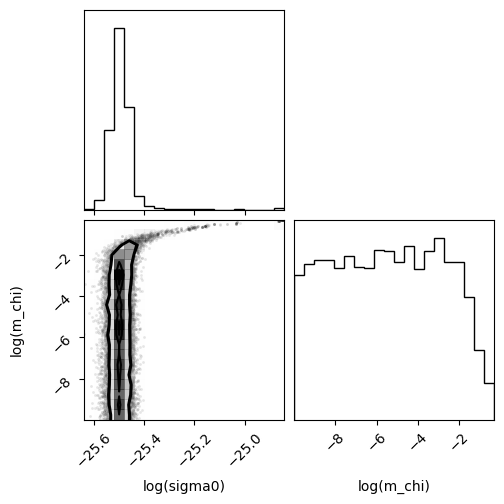

In [75]:
flat_samples = sampler.get_chain(discard=100, thin=15, flat=True)
print(flat_samples.shape)
fig = corner.corner(flat_samples, labels=['log(sigma0)', 'log(m_chi)'])

In [44]:
# should have had prefactors as a free parameter and given logmchi and logsigma0 to predict temperature once again
from scipy.optimize import root
p0=-42 #-41 gives closer to actual temp
x0=1e-5 * u.GeV 
solution = root(funp, x0, args=(test_cluster, p0), method='df-sane').x
print(solution)
print(test_cluster.baryon_temp)

1.621827841475169483e-05
1.133690517119171e-05 GeV


In [53]:
p0s=np.linspace(-50, -30)
solns_df=[root(funp, x0, args=(test_cluster, p), method='df-sane').x for p in p0s]
solns_an=[root(funp, x0, args=(test_cluster, p), method='anderson').x for p in p0s]

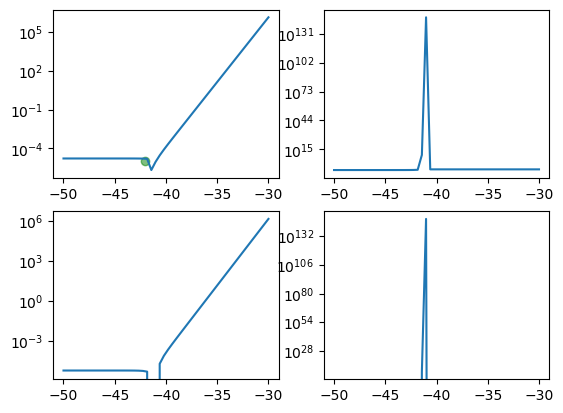

In [83]:
fig, axs = plt.subplots(2, 2)
axs[0,0].set_yscale('log')
axs[0,1].set_yscale('log')
axs[1,0].set_yscale('log')
axs[1,1].set_yscale('log')

axs[0, 0].plot(p0s, solns_df)
axs[0,0].scatter(-42,test_cluster.baryon_temp.value, color='green', alpha=0.5)


#axs[0,0].title('df-sane solve')
axs[0, 1].plot(p0s, solns_an)
#axs[0,0].title('anderson solve')
axs[1, 0].plot(p0s, solns_df - test_cluster.baryon_temp.value)
axs[1, 1].plot(p0s, solns_an - test_cluster.baryon_temp.value)

In [80]:
solns_df

[array(1.68943521e-05, dtype=float128),
 array(1.68943521e-05, dtype=float128),
 array(1.6894352e-05, dtype=float128),
 array(1.6894352e-05, dtype=float128),
 array(1.68943518e-05, dtype=float128),
 array(1.68943513e-05, dtype=float128),
 array(1.68943502e-05, dtype=float128),
 array(1.68943472e-05, dtype=float128),
 array(1.68943396e-05, dtype=float128),
 array(1.68943202e-05, dtype=float128),
 array(1.68942706e-05, dtype=float128),
 array(1.68941434e-05, dtype=float128),
 array(1.68938181e-05, dtype=float128),
 array(1.68929852e-05, dtype=float128),
 array(1.68908535e-05, dtype=float128),
 array(1.68853973e-05, dtype=float128),
 array(1.68714319e-05, dtype=float128),
 array(1.68356869e-05, dtype=float128),
 array(1.67441971e-05, dtype=float128),
 array(1.65100335e-05, dtype=float128),
 array(1.59101279e-05, dtype=float128),
 array(2.15474734e-06, dtype=float128),
 array(9.08297865e-06, dtype=float128),
 array(2.92300646e-05, dtype=float128),
 array(8.20518322e-05, dtype=float128),
 a

In [81]:
np.min(solns_df)

2.1547473367622390065e-06

In [89]:
np.min(np.abs(solns_df - test_cluster.baryon_temp.value))

2.2539265226157141512e-06

In [95]:
# mcmc with prefactors as free param
ndim, nwalkers = 1, 5
rng = np.random.default_rng()
p0=rng.uniform(low=-50, high=-30, size=(nwalkers, ndim))#.astype(dtype=np.float128)
p0

array([[-36.18441674],
       [-43.39646153],
       [-32.72593274],
       [-35.41981251],
       [-39.94763983]])

In [96]:
T_data = [c.baryon_temp for c in clusters]
T_var=[t/10 for t in T_data] #fake variance
sampler = emcee.EnsembleSampler(nwalkers, ndim, log_likelihood, args=[T_data, T_var, clusters, 'pred_Tb_pref'])

In [97]:
p0.shape

(5, 1)

In [98]:
state = sampler.run_mcmc(p0, 50, progress=True)
sampler.reset()

[-36.18441674] 0.9111710686008885
[-36.18441674] 0.9111722687249373
[-36.18441674] 0.9111724379494504
[-36.18441674] 0.9111726864987901
[-36.18441674] 0.9111727285538099
[-36.18441674] 0.9111728047207713
[-36.18441674] 0.9111728101800748
[-36.18441674] 0.9111728860204366
[-36.18441674] 0.9111730161841676
[-36.18441674] 0.9111730745836548
[-36.18441674] 0.9111730371052945
[-36.18441674] 0.9111731630453221
[-36.18441674] 0.9111732422878144
[-36.18441674] 0.9111733629915205
[-36.18441674] 0.9111734823156747
[-36.18441674] 0.9111735599842717
[-36.18441674] 0.9111736248964015
[-36.18441674] 0.9111735555398071
[-36.18441674] 0.911173620284919
[-36.18441674] 0.9111736091068151
[-36.18441674]
[-43.39646153] 1.6867241122934176e-05
[-43.39646153] 1.6449802563599313e-05
[-43.39646153] 1.638870876797594e-05
[-43.39646153] 1.629788606949307e-05
[-43.39646153] 1.6282386915473718e-05
[-43.39646153] 1.6254216823763195e-05
[-43.39646153] 1.6252192775930598e-05
[-43.39646153] 1.6224005783649027e-05
[-43

You must install the tqdm library to use progress indicators with emcee


[-43.39646153] 1.604368101059472e-05
[-43.39646153] 1.6000238473317813e-05
[-43.39646153] 1.5970111127787797e-05
[-43.39646153] 1.5944813538649714e-05
[-43.39646153] 1.597183926395924e-05
[-43.39646153] 1.5946614318009598e-05
[-43.39646153] 1.5950977070566885e-05
[-43.39646153]
[-32.72593274] 2618.7038997531868
[-32.72593274] 2618.703901567691
[-32.72593274] 2618.7039018151418
[-32.72593274] 2618.7039021744763
[-32.72593274] 2618.70390223478
[-32.72593274] 2618.7039023436246
[-32.72593274] 2618.7039023514044
[-32.72593274] 2618.703902459264
[-32.72593274] 2618.7039026432312
[-32.72593274] 2618.703902725292
[-32.72593274] 2618.7039026726634
[-32.72593274] 2618.7039028490235
[-32.72593274] 2618.7039029592634
[-32.72593274] 2618.703903126081
[-32.72593274] 2618.7039032896614
[-32.72593274] 2618.7039033954106
[-32.72593274] 2618.7039034833424
[-32.72593274] 2618.703903389374
[-32.72593274] 2618.70390347711
[-32.72593274] 2618.70390346199
[-32.72593274]
[-35.41981251] 5.299149761015021
[-35

[-44.22706485] 1.6411789815793224e-05
[-44.22706485] 1.63209626642788e-05
[-44.22706485] 1.6305462764662152e-05
[-44.22706485] 1.627729132891218e-05
[-44.22706485] 1.6275267185067605e-05
[-44.22706485] 1.624707886362731e-05
[-44.22706485] 1.6198395703894266e-05
[-44.22706485] 1.617642662735012e-05
[-44.22706485] 1.619053457731075e-05
[-44.22706485] 1.6142996460881116e-05
[-44.22706485] 1.6112892513122786e-05
[-44.22706485] 1.6066745957271808e-05
[-44.22706485] 1.6023311206080324e-05
[-44.22706485] 1.5993182597934824e-05
[-44.22706485] 1.5967883964789396e-05
[-44.22706485] 1.599491080596818e-05
[-44.22706485] 1.596968481797027e-05
[-44.22706485] 1.5974047749690222e-05
[-44.22706485]
[-34.36441604] 60.20090911005512
[-34.36441604] 60.200910310185115
[-34.36441604] 60.20091047941035
[-34.36441604] 60.20091072796066
[-34.36441604] 60.20091077001583
[-34.36441604] 60.20091084618312
[-34.36441604] 60.2009108516424
[-34.36441604] 60.20091092748308
[-34.36441604] 60.200911057647254
[-34.364416

[-47.92663592] 1.6251076713541217e-05
[-47.92663592] 1.6202393161875288e-05
[-47.92663592] 1.618042391108819e-05
[-47.92663592] 1.61945319727527e-05
[-47.92663592] 1.6146993482693557e-05
[-47.92663592] 1.6116889302470903e-05
[-47.92663592] 1.6070742396713383e-05
[-47.92663592] 1.6027308994311038e-05
[-47.92663592] 1.5997180167201497e-05
[-47.92663592] 1.597188135300292e-05
[-47.92663592] 1.599890838769728e-05
[-47.92663592] 1.597368221898593e-05
[-47.92663592] 1.5978045181776538e-05
[-47.92663592]
[-47.514385] 1.689435002065768e-05
[-47.514385] 1.6476885182844554e-05
[-47.514385] 1.6415787782213508e-05
[-47.514385] 1.6324959858709166e-05
[-47.514385] 1.63094598298334e-05
[-47.514385] 1.6281288161076203e-05
[-47.514385] 1.6279264000586746e-05
[-47.514385] 1.6251075448718715e-05
[-47.514385] 1.62023918971768e-05
[-47.514385] 1.618042264644477e-05
[-47.514385] 1.619453070807392e-05
[-47.514385] 1.614699221813305e-05
[-47.514385] 1.6116888037984e-05
[-47.514385] 1.60707411323371e-05
[-47.5

[-42.49403018] 1.5782679743456234e-05
[-42.49403018] 1.575746327925839e-05
[-42.49403018] 1.576182457353329e-05
[-42.49403018]
[-38.10223019] 0.011004856008488828
[-38.10223019] 0.011006055638441937
[-38.10223019] 0.011006224803679153
[-38.10223019] 0.011006473270615791
[-38.10223019] 0.011006515312241756
[-38.10223019] 0.011006591455347511
[-38.10223019] 0.011006596912961396
[-38.10223019] 0.011006672730124662
[-38.10223019] 0.011006802855244519
[-38.10223019] 0.01100686123790278
[-38.10223019] 0.011006823770307228
[-38.10223019] 0.011006949674659577
[-38.10223019] 0.011007028895434855
[-38.10223019] 0.01100714956714431
[-38.10223019] 0.011007268860952288
[-38.10223019] 0.011007346510483802
[-38.10223019] 0.011007411407095052
[-38.10223019] 0.011007342067095516
[-38.10223019] 0.011007406796702436
[-38.10223019] 0.011007395621248639
[-38.10223019]
[-42.09239652] 1.6347694450788918e-05
[-42.09239652] 1.5931417734706276e-05
[-42.09239652] 1.587039163038489e-05
[-42.09239652] 1.5779667029

... (14 outputs left out)

[-41.22796962] 5.439155395584205e-06
[-41.22796962] 5.485612641775113e-06
[-41.22796962] 5.488963654253251e-06
[-41.22796962] 5.535810617365078e-06
[-41.22796962] 5.6175073721959145e-06
[-41.22796962] 5.654698916981606e-06
[-41.22796962] 5.63079243140109e-06
[-41.22796962] 5.711676668372823e-06
[-41.22796962] 5.7633782862566535e-06
[-41.22796962] 5.843347001272329e-06
[-41.22796962] 5.9238624029533304e-06
[-41.22796962] 5.97705983983014e-06
[-41.22796962] 6.022002234304483e-06
[-41.22796962] 5.973998784930903e-06
[-41.22796962] 6.018794879971378e-06
[-41.22796962] 6.0110296010693075e-06
[-41.22796962]
[-41.25067635] 4.2004066153747126e-06
[-41.25067635] 4.7940669752158085e-06
[-41.25067635] 4.887704950104783e-06
[-41.25067635] 5.030076090093647e-06
[-41.25067635] 5.054748330583777e-06
[-41.25067635] 5.099869949934307e-06
[-41.25067635] 5.103125821558103e-06
[-41.25067635] 5.148659514316736e-06
[-41.25067635] 5.22814039432435e-06
[-41.25067635] 5.264354144581662e-06
[-41.25067635] 5.241

[-41.21484969] 5.672096549296142e-06
[-41.21484969] 5.719308567502842e-06
[-41.21484969] 5.7227133244217495e-06
[-41.21484969] 5.7703018687648335e-06
[-41.21484969] 5.853248718419136e-06
[-41.21484969] 5.890991420857499e-06
[-41.21484969] 5.866731933161487e-06
[-41.21484969] 5.9487920914057965e-06
[-41.21484969] 6.0012182183488844e-06
[-41.21484969] 6.082266581371569e-06
[-41.21484969] 6.163819611863515e-06
[-41.21484969] 6.2176759169716485e-06
[-41.21484969] 6.263158632741113e-06
[-41.21484969] 6.214577519594334e-06
[-41.21484969] 6.2599132086711335e-06
[-41.21484969] 6.252055448215743e-06
[-41.21484969]
[-41.12930363] 6.386539107014764e-06
[-41.12930363] 7.100437842897831e-06
[-41.12930363] 7.209896784022834e-06
[-41.12930363] 7.374822519366546e-06
[-41.12930363] 7.403224556817988e-06
[-41.12930363] 7.455033936519456e-06
[-41.12930363] 7.4587657610724445e-06
[-41.12930363] 7.510863302526612e-06
[-41.12930363] 7.601394255852874e-06
[-41.12930363] 7.642474064046657e-06
[-41.12930363] 7

[-41.07528746] 8.958684645336987e-06
[-41.07528746] 8.931087742348341e-06
[-41.07528746] 9.02425090123726e-06
[-41.07528746] 9.083497060570134e-06
[-41.07528746] 9.174679202318706e-06
[-41.07528746] 9.265938652911793e-06
[-41.07528746] 9.325941559976858e-06
[-41.07528746] 9.376455268787946e-06
[-41.07528746] 9.322495140407014e-06
[-41.07528746] 9.372855658473547e-06
[-41.07528746] 9.364137304925605e-06
[-41.07528746]
[-41.21569382] 4.753842853794167e-06
[-41.21569382] 5.383394094190124e-06
[-41.21569382] 5.48182371977207e-06
[-41.21569382] 5.631054581905675e-06
[-41.21569382] 5.656864472214898e-06
[-41.21569382] 5.704028311360014e-06
[-41.21569382] 5.707429638059703e-06
[-41.21569382] 5.754970857077758e-06
[-41.21569382] 5.837837954363692e-06
[-41.21569382] 5.8755455044309685e-06
[-41.21569382] 5.851308530216382e-06
[-41.21569382] 5.933293701161779e-06
[-41.21569382] 5.9856736406605165e-06
[-41.21569382] 6.066653195674404e-06
[-41.21569382] 6.148140118239465e-06
[-41.21569382] 6.201954

[-41.22022667] 5.983382625902198e-06
[-41.22022667] 6.064513022879969e-06
[-41.22022667] 6.118101012176037e-06
[-41.22022667] 6.163363715545953e-06
[-41.22022667] 6.115017821099653e-06
[-41.22022667] 6.160133792231642e-06
[-41.22022667] 6.152313687747455e-06
[-41.22022667]
[-41.21747352] 4.7242843430269715e-06
[-41.21747352] 5.352029714980284e-06
[-41.21747352] 5.450219741978667e-06
[-41.21747352] 5.599108222274717e-06
[-41.21747352] 5.62486140212054e-06
[-41.21747352] 5.671923490573038e-06
[-41.21747352] 5.675317572707329e-06
[-41.21747352] 5.722758838841635e-06
[-41.21747352] 5.805457485130191e-06
[-41.21747352] 5.8430907828344315e-06
[-41.21747352] 5.8189013641624505e-06
[-41.21747352] 5.900728134094082e-06
[-41.21747352] 5.95301050244775e-06
[-41.21747352] 6.033844691608543e-06
[-41.21747352] 6.115191942767704e-06
[-41.21747352] 6.168917613307835e-06
[-41.21747352] 6.2142932164703675e-06
[-41.21747352] 6.165826619239761e-06
[-41.21747352] 6.211055338778779e-06
[-41.21747352] 6.2032

In [99]:
n_steps=500
sampler.run_mcmc(state, n_steps, progress=True)

You must install the tqdm library to use progress indicators with emcee


[-41.21599549] 4.748821691756295e-06
[-41.21599549] 5.3780669940999284e-06
[-41.21599549] 5.476456039377727e-06
[-41.21599549] 5.625628917558148e-06
[-41.21599549] 5.651429204205484e-06
[-41.21599549] 5.69857581269964e-06
[-41.21599549] 5.701975912609398e-06
[-41.21599549] 5.74950020591957e-06
[-41.21599549] 5.832338779289606e-06
[-41.21599549] 5.870033756575498e-06
[-41.21599549] 5.845804834673591e-06
[-41.21599549] 5.927763184875732e-06
[-41.21599549] 5.9801266040377794e-06
[-41.21599549] 6.061081547145202e-06
[-41.21599549] 6.142544822869979e-06
[-41.21599549] 6.19634415091929e-06
[-41.21599549] 6.241780149932457e-06
[-41.21599549] 6.1932489825023594e-06
[-41.21599549] 6.238538017155499e-06
[-41.21599549] 6.230688252291871e-06
[-41.21599549]
[-41.2089386] 4.867449890778347e-06
[-41.2089386] 5.503834016873885e-06
[-41.2089386] 5.603168823279477e-06
[-41.2089386] 5.753692592918167e-06
[-41.2089386] 5.7797165680073614e-06
[-41.2089386] 5.827264473669359e-06
[-41.2089386] 5.830693143266

[-41.2289542] 5.421999394783273e-06
[-41.2289542] 5.4683994910562735e-06
[-41.2289542] 5.471746433517507e-06
[-41.2289542] 5.518537229354335e-06
[-41.2289542] 5.600139268217378e-06
[-41.2289542] 5.637289039842185e-06
[-41.2289542] 5.61340930984206e-06
[-41.2289542] 5.694204405277638e-06
[-41.2289542] 5.7458510822759385e-06
[-41.2289542] 5.825737898592573e-06
[-41.2289542] 5.906174558478576e-06
[-41.2289542] 5.959321980688761e-06
[-41.2289542] 6.004223350313841e-06
[-41.2289542] 5.956263760780695e-06
[-41.2289542] 6.001018886761121e-06
[-41.2289542] 5.9932606301667295e-06
[-41.2289542]
[-41.19741741] 5.0664419961027245e-06
[-41.19741741] 5.714397228347026e-06
[-41.19741741] 5.815259962863737e-06
[-41.19741741] 5.967964088311672e-06
[-41.19741741] 5.994348861712266e-06
[-41.19741741] 6.042543869782982e-06
[-41.19741741] 6.046018600432327e-06
[-41.19741741] 6.094572373748795e-06
[-41.19741741] 6.179145103636589e-06
[-41.19741741] 6.217604156681439e-06
[-41.19741741] 6.1928858995254935e-06

[-41.20450627] 6.044845174493467e-06
[-41.20450627] 6.083015136209652e-06
[-41.20450627] 6.058482016008419e-06
[-41.20450627] 6.141453478635185e-06
[-41.20450627] 6.194440764217012e-06
[-41.20450627] 6.27632490746454e-06
[-41.20450627] 6.358680685057709e-06
[-41.20450627] 6.413046456654196e-06
[-41.20450627] 6.4589468233249145e-06
[-41.20450627] 6.409919189758397e-06
[-41.20450627] 6.455671977003782e-06
[-41.20450627] 6.447742739250753e-06
[-41.20450627]
[-41.20651481] 4.9087616022872515e-06
[-41.20651481] 5.547588830067501e-06
[-41.20651481] 5.647246754580421e-06
[-41.20651481] 5.798231827303043e-06
[-41.20651481] 5.824332161670818e-06
[-41.20651481] 5.8720170373394134e-06
[-41.20651481] 5.875455457378398e-06
[-41.20651481] 5.9235083964186576e-06
[-41.20651481] 6.007237665670231e-06
[-41.20651481] 6.045325164162292e-06
[-41.20651481] 6.020844855365116e-06
[-41.20651481] 6.103640449933056e-06
[-41.20651481] 6.156519461394412e-06
[-41.20651481] 6.238242372874309e-06
[-41.20651481] 6.320

[-41.20532197] 6.179017015126702e-06
[-41.20532197] 6.260835742034245e-06
[-41.20532197] 6.343128704425963e-06
[-41.20532197] 6.397454618095238e-06
[-41.20532197] 6.4433223146320205e-06
[-41.20532197] 6.394329609629892e-06
[-41.20532197] 6.4400497696867715e-06
[-41.20532197] 6.432126122895233e-06
[-41.20532197]
[-41.19780456] 5.059646723965204e-06
[-41.19780456] 5.70721488304328e-06
[-41.19780456] 5.8080266049425805e-06
[-41.19780456] 5.960657976285043e-06
[-41.19780456] 5.987030715243256e-06
[-41.19780456] 6.035204142527413e-06
[-41.19780456] 6.038677337210055e-06
[-41.19780456] 6.0872099265869554e-06
[-41.19780456] 6.1717469876947085e-06
[-41.19780456] 6.210190331140996e-06
[-41.19780456] 6.185482134409339e-06
[-41.19780456] 6.269036572051951e-06
[-41.19780456] 6.3223826981464185e-06
[-41.19780456] 6.40480109244506e-06
[-41.19780456] 6.487669779519309e-06
[-41.19780456] 6.542360955841129e-06
[-41.19780456] 6.588528016192965e-06
[-41.19780456] 6.5392152518990445e-06
[-41.19780456] 6.5

[-41.20624491] 5.803209121891558e-06
[-41.20624491] 5.829317944267341e-06
[-41.20624491] 5.8770180447814815e-06
[-41.20624491] 5.8804575485984385e-06
[-41.20624491] 5.928525437495903e-06
[-41.20624491] 6.012279889241638e-06
[-41.20624491] 6.0503784830314695e-06
[-41.20624491] 6.025891068512947e-06
[-41.20624491] 6.1087103263608335e-06
[-41.20624491] 6.161603906831467e-06
[-41.20624491] 6.243348513954236e-06
[-41.20624491] 6.325570300582716e-06
[-41.20624491] 6.379851049697517e-06
[-41.20624491] 6.42568172550078e-06
[-41.20624491] 6.376728600380654e-06
[-41.20624491] 6.422411788427765e-06
[-41.20624491] 6.414494477182186e-06
[-41.20624491]
[-41.20067985] 5.009416684715945e-06
[-41.20067985] 5.654106227249946e-06
[-41.20067985] 5.754538360427109e-06
[-41.20067985] 5.906628274611646e-06
[-41.20067985] 5.932911439677504e-06
[-41.20067985] 5.980924231206338e-06
[-41.20067985] 5.984385992626717e-06
[-41.20067985] 6.032760890495668e-06
[-41.20067985] 6.117032415863868e-06
[-41.20067985] 6.155

... (211 outputs left out)

[-41.20604036] 6.02971781154802e-06
[-41.20604036] 6.112554996858179e-06
[-41.20604036] 6.165459614788745e-06
[-41.20604036] 6.24722065832717e-06
[-41.20604036] 6.329458228813299e-06
[-41.20604036] 6.3837489937185005e-06
[-41.20604036] 6.4295878794073254e-06
[-41.20604036] 6.380625976876169e-06
[-41.20604036] 6.426317363998192e-06
[-41.20604036] 6.418398647748636e-06
[-41.20604036]
[-41.21011293] 4.847539088544516e-06
[-41.21011293] 5.4827378868485725e-06
[-41.21011293] 5.5819158248480465e-06
[-41.21011293] 5.732215598028678e-06
[-41.21011293] 5.75820249034338e-06
[-41.21011293] 5.805683875114345e-06
[-41.21011293] 5.809107809142603e-06
[-41.21011293] 5.856960917726606e-06
[-41.21011293] 5.940353548374112e-06
[-41.21011293] 5.9782927127968715e-06
[-41.21011293] 5.953907401936536e-06
[-41.21011293] 6.0363866246853455e-06
[-41.21011293] 6.0890708348442044e-06
[-41.21011293] 6.170503630451596e-06
[-41.21011293] 6.252425953376474e-06
[-41.21011293] 6.306516658896859e-06
[-41.21011293] 6.35

[-41.21158591] 6.142950985004505e-06
[-41.21158591] 6.22475877312037e-06
[-41.21158591] 6.278776785190449e-06
[-41.21158591] 6.324392079224544e-06
[-41.21158591] 6.275669223997022e-06
[-41.21158591] 6.3211373150009795e-06
[-41.21158591] 6.313256864192809e-06
[-41.21158591]
[-41.19828536] 5.051218225450754e-06
[-41.19828536] 5.698305503120255e-06
[-41.19828536] 5.7990538398689466e-06
[-41.19828536] 5.951594807506249e-06
[-41.19828536] 5.977952592110338e-06
[-41.19828536] 6.026099202151772e-06
[-41.19828536] 6.029570488158422e-06
[-41.19828536] 6.078076753004273e-06
[-41.19828536] 6.162569488885887e-06
[-41.19828536] 6.200993309817337e-06
[-41.19828536] 6.176297615326185e-06
[-41.19828536] 6.259810425170629e-06
[-41.19828536] 6.313130931576983e-06
[-41.19828536] 6.395511187730442e-06
[-41.19828536] 6.4783432659254276e-06
[-41.19828536] 6.53301121944908e-06
[-41.19828536] 6.579159248676379e-06
[-41.19828536] 6.529866831222072e-06
[-41.19828536] 6.575866957056864e-06
[-41.19828536] 6.56789

[-41.2111716] 5.712910914816016e-06
[-41.2111716] 5.738864328291295e-06
[-41.2111716] 5.78628565517234e-06
[-41.2111716] 5.789705313633746e-06
[-41.2111716] 5.837499439319989e-06
[-41.2111716] 5.920792694918583e-06
[-41.2111716] 5.9586880669349515e-06
[-41.2111716] 5.934330802464818e-06
[-41.2111716] 6.0167166178824965e-06
[-41.2111716] 6.069343307605401e-06
[-41.2111716] 6.150690429674776e-06
[-41.2111716] 6.232530461162565e-06
[-41.2111716] 6.286568938054169e-06
[-41.2111716] 6.332201009596576e-06
[-41.2111716] 6.283460217167518e-06
[-41.2111716] 6.328945063423194e-06
[-41.2111716] 6.321061741246748e-06
[-41.2111716]
[-41.21671684] 4.736832957155239e-06
[-41.21671684] 5.3653464200108864e-06
[-41.21671684] 5.463638374486582e-06
[-41.21671684] 5.612672515096741e-06
[-41.21671684] 5.638449822310028e-06
[-41.21671684] 5.685555201061996e-06
[-41.21671684] 5.688952365461561e-06
[-41.21671684] 5.736436157876507e-06
[-41.21671684] 5.819206475698706e-06
[-41.21671684] 5.85687136658769e-06
[-4

State([[-41.21671684]
 [-41.19736112]
 [-41.20563589]
 [-41.21357548]
 [-41.2111716 ]], log_prob=[-112.08792171 -113.22165526 -111.94508594 -111.84083934 -111.76060021], blobs=None, random_state=('MT19937', array([1931869203, 2598751574,  770095684, 1754667350, 2973583833,
       3835197322, 2127518011, 2414942480, 2231569928, 4058694707,
       1516781786, 2290581275, 4038572707, 2701400016, 3676558765,
       1699524760, 3255907221, 1859974427, 4023821332, 3240856203,
       3081200601,  657602418, 3576659186, 3290332111,  450718927,
        598710910, 3285203351,    1375174,  485874789, 1340164035,
       2090360517,   72292175, 4130759130, 2293524999,  385826881,
       1299493498, 2011773921, 3654020196,  288936988,  847725307,
        825551981, 3343367848, 3207352740, 3129679368, 3635822745,
       3960733160, 2549472636,  214727858, 2178046876, 1242080806,
        987904189, 2846209076, 4102665711, 1900547632, 3901199391,
       1083327373, 1545327491, 3832127815, 4100485043, 1

In [90]:
samples = sampler.get_chain(flat=True)

In [91]:
"Mean acceptance fraction: {0:.3f}".format(np.mean(sampler.acceptance_fraction))

'Mean acceptance fraction: 0.600'

(165, 1)


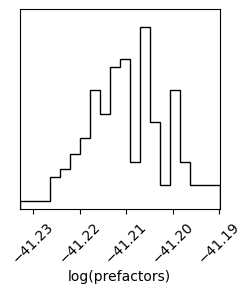

In [100]:
flat_samples = sampler.get_chain(thin=15, flat=True)
print(flat_samples.shape)
fig = corner.corner(flat_samples, labels=['log(prefactors)'])

In [101]:
np.median(samples)

-41.20494601087451

In [103]:
10**-41.20494601087451 # actual is 6.8*10^-42

6.238123796211007e-42

In [102]:
test_cluster.pred_Tb_pref(16) 

16 1.3932181767510939359e+52


<Quantity 1.39321818e+52 GeV>

In [8]:
test_cluster.pred_Tb_pref(-42)

[1.85998479e-07]


/Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/astropy/units/quantity.py:611: RuntimeWarning: invalid value encountered in power
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


<Quantity 1.85998479e-07 GeV>